# Chapitre 7 - Exercices 7.7 à 7.12

Ce notebook traite les derniers exercices du chapitre 7, centrés sur le routage des
requêtes, les index secondaires et l'exploitation d'un cluster partitionné :

- **7.7** : trouver l'anomalie, une écriture perdue pendant le déplacement d'un shard
  (raisonnement et mini-lab) ;
- **7.8** : scatter/gather et latence de queue, requêtes de couverture (calcul et
  simulation) ;
- **7.9** : index secondaire local ou global, un modèle de coût (calcul et mini-lab) ;
- **7.10** : rééquilibrage automatique, durée des transferts et seuil de la
  défaillance en cascade (calcul et simulation).

Deux exercices portent sur des notions propres à la 2e édition :

- **7.11** : sharding pour la multi-location, ranger des locataires, voisins
  bruyants et croissance (calcul et mini-lab) ;
- **7.12** : faut-il sharder ? capacité d'une seule machine et transactions
  multi-shards (calcul).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import partitioning as P
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 7.7 : trouver l'anomalie, une écriture perdue pendant un déplacement

**Énoncé.** Un cluster utilise une couche de routage qui reçoit la carte
« shard -> nœud » d'un service de coordination. Voici la trace d'un incident :

- t = 10,0 : le coordinateur décide de déplacer le shard 3 du nœud A vers le nœud B ;
  les données sont copiées, B devient propriétaire et sert désormais le shard 3 ;
- t = 10,4 : le routeur, qui n'a pas encore reçu la nouvelle carte, envoie l'écriture
  `x = 5` (clé de du shard 3) au nœud A, qui l'applique sur sa copie locale et répond OK ;
- t = 11,2 : la nouvelle carte arrive au routeur ;
- t = 12,0 : un client lit `x` : la requête va à B, qui renvoie l'ancienne valeur.

1. Expliquer l'anomalie. Quel composant a mal agi, et pourquoi la carte périmée du
   routeur n'est-elle pas en soi la faute ?
2. Proposer une correction qui ne suppose pas que les cartes se propagent
   instantanément.
3. Simuler 1 000 secondes de trafic (200 écritures/s sur le shard, un déplacement toutes
   les 50 s, délai de propagation de la carte uniforme entre 0 et 2 s) et compter les
   écritures perdues avec et sans correction.

**Rappels.** Le routage repose sur une carte des affectations publiée par un service de
coordination (ZooKeeper par exemple) ; pendant la bascule d'un shard, des requêtes
adressées à l'ancien propriétaire peuvent encore être en vol (cours 3, section *Request
Routing*). Le chapitre 9 reviendra sur les numéros d'époque et les jetons de
clôture.

**Solution.**

*1.* La carte du routeur est périmée pendant 1,2 s : c'est **inévitable** dans un
système distribué, la nouvelle version met du temps à se propager. La faute est celle du
nœud A : il a accepté une écriture pour un shard qu'il ne possède plus, et l'a
acquittée. L'écriture vit sur une copie que plus personne ne lit : elle est **perdue**,
alors que le client a reçu un OK. Un routeur périmé ne doit provoquer que des détours,
jamais des pertes.

*2.* Deux mécanismes complémentaires :

- **contrôle de propriété** : chaque nœud vérifie, pour chaque requête, qu'il possède
  le shard visé ; sinon il refuse en indiquant le nouveau propriétaire (redirection, à
  la manière de la réponse `MOVED` de Redis Cluster) ou relaie la requête ;
- **numéro de version (époque) de la carte** : chaque requête porte la version de carte
  utilisée par le routeur ; un nœud refuse une requête plus ancienne que la version qui
  lui a retiré le shard. Le routeur, sur refus, rafraîchit sa carte et réessaie.

Le coût : quelques requêtes font un aller-retour de plus pendant la fenêtre de
propagation. Le gain : aucune perte, quel que soit le retard de la carte.

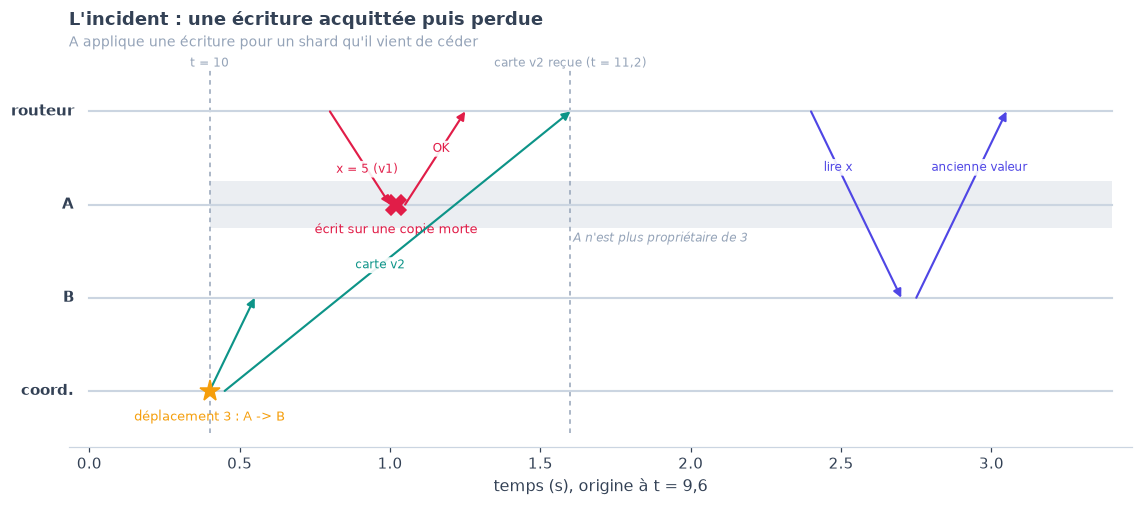

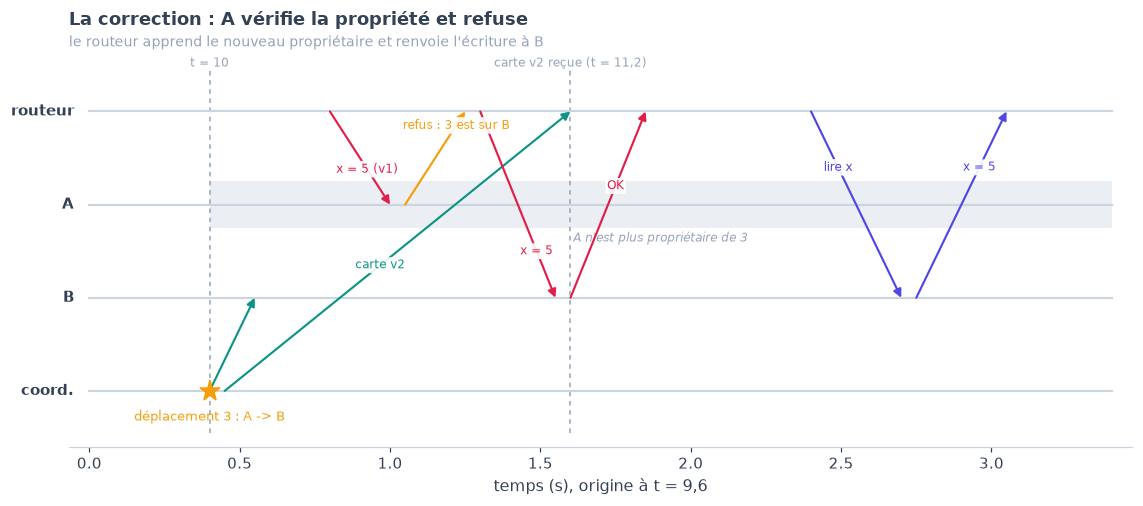

In [2]:
T0 = 9.6   # origine de l'axe : les instants affichés sont t - 9,6
def trace(titre, sous_titre, corrige):
    st = SpaceTime(["routeur", "A", "B", "coord."], t_max=3.4, width=10.5, title=titre, subtitle=sous_titre,
                   time_label="temps (s), origine à t = 9,6")
    st.span("A", 10.0 - T0, 3.4, "A n'est plus propriétaire de 3", color=GRAY, alpha=0.18)
    st.event("coord.", 10.0 - T0, "déplacement 3 : A -> B", kind="star")
    st.msg("coord.", 10.0 - T0, "B", 10.15 - T0, "", color=TEAL)
    st.msg("coord.", 10.05 - T0, "routeur", 11.2 - T0, "carte v2", color=TEAL, label_pos=0.45)
    st.msg("routeur", 10.4 - T0, "A", 10.6 - T0, "x = 5 (v1)", color=ROSE, label_pos=0.62)
    if not corrige:
        st.msg("A", 10.65 - T0, "routeur", 10.85 - T0, "OK", color=ROSE, label_pos=0.6)
        st.event("A", 10.62 - T0, "écrit sur une copie morte", kind="crash")
        st.msg("routeur", 12.0 - T0, "B", 12.3 - T0, "lire x", color=INDIGO, label_pos=0.3)
        st.msg("B", 12.35 - T0, "routeur", 12.65 - T0, "ancienne valeur", color=INDIGO, label_pos=0.7)
    else:
        st.msg("A", 10.65 - T0, "routeur", 10.85 - T0, "refus : 3 est sur B", color=AMBER, label_pos=0.85)
        st.msg("routeur", 10.9 - T0, "B", 11.15 - T0, "x = 5", color=ROSE, label_pos=0.75)
        st.msg("B", 11.2 - T0, "routeur", 11.45 - T0, "OK", color=ROSE, label_pos=0.6)
        st.msg("routeur", 12.0 - T0, "B", 12.3 - T0, "lire x", color=INDIGO, label_pos=0.3)
        st.msg("B", 12.35 - T0, "routeur", 12.65 - T0, "x = 5", color=INDIGO, label_pos=0.7)
    st.vline(10.0 - T0, "t = 10")
    st.vline(11.2 - T0, "carte v2 reçue (t = 11,2)")
    st.show()

trace("L'incident : une écriture acquittée puis perdue",
      "A applique une écriture pour un shard qu'il vient de céder", corrige=False)
trace("La correction : A vérifie la propriété et refuse",
      "le routeur apprend le nouveau propriétaire et renvoie l'écriture à B", corrige=True)

**Vérification.** Un petit modèle : les écritures arrivent selon un processus de Poisson ;
chaque déplacement change le propriétaire à l'instant $t_d$, et le routeur ne l'apprend
qu'à $t_d + \delta$. Sans correction, toute écriture routée vers l'ancien propriétaire
pendant cette fenêtre est perdue ; avec correction, elle est refusée puis renvoyée au
bon nœud (un aller-retour de plus, 1 ms ici).

In [3]:
def simule_routage(duree=1_000.0, debit=200.0, periode=50.0, delai_max=2.0, correction=False, seed=0):
    r = np.random.default_rng(seed)
    t_ecr = np.sort(r.uniform(0, duree, r.poisson(debit * duree)))
    t_dep = np.arange(periode, duree, periode)
    delais = r.uniform(0, delai_max, t_dep.size)
    # pour chaque écriture : y a-t-il un déplacement récent que le routeur ignore encore ?
    k = np.searchsorted(t_dep, t_ecr, side="right") - 1        # dernier déplacement avant l'écriture
    perime = (k >= 0) & (t_ecr < t_dep[np.maximum(k, 0)] + delais[np.maximum(k, 0)])
    latence = np.full(t_ecr.size, 1.0)                           # 1 ms par aller-retour
    if correction:
        latence[perime] += 1.0                                   # refus + nouvel envoi
        perdues = 0
    else:
        perdues = int(perime.sum())
    return {"écritures": t_ecr.size, "attendu sans correction : débit × Σ délais": debit * delais.sum(), "routées vers l'ancien nœud": int(perime.sum()),
            "perdues": perdues, "latence moyenne (ms)": latence.mean(),
            "latence max (ms)": latence.max()}

tab = pd.DataFrame({"sans correction": simule_routage(), "contrôle + époque": simule_routage(correction=True)}).T
attendu = 200 * 1.0 * (1_000 // 50 - 0)          # débit × délai moyen × nombre de déplacements
tab

,écritures,attendu sans correction : débit × Σ délais,routées vers l'ancien nœud,perdues,latence moyenne (ms),latence max (ms)
sans correction,200176.0,2657.983,2627.0,2627.0,1.000,1.0
contrôle + époque,200176.0,2657.983,2627.0,0.0,1.013,2.0


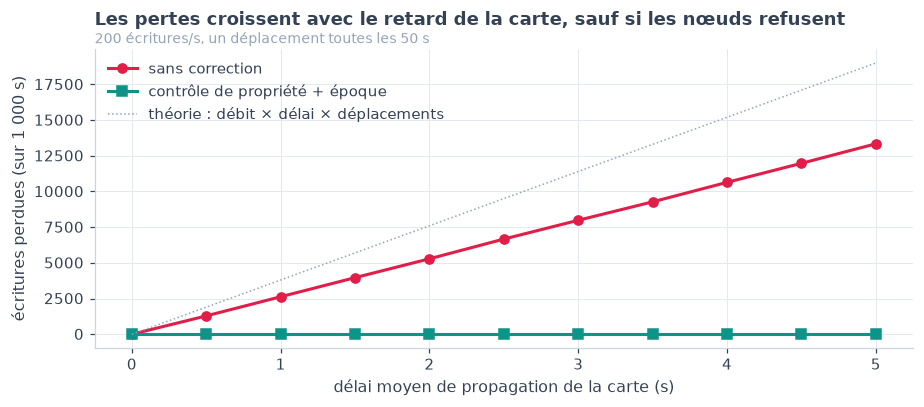

In [4]:
delais = np.linspace(0, 5, 11)
pertes = [simule_routage(delai_max=2 * d)["perdues"] for d in delais]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(delais, pertes, "o-", color=ROSE, label="sans correction")
ax.plot(delais, np.zeros_like(delais), "s-", color=TEAL, label="contrôle de propriété + époque")
ax.plot(delais, 200 * delais * 19, color=GRAY, lw=1, ls=":", label="théorie : débit × délai × déplacements")
ax.set_xlabel("délai moyen de propagation de la carte (s)")
ax.set_ylabel("écritures perdues (sur 1 000 s)")
ax.set_title("Les pertes croissent avec le retard de la carte, sauf si les nœuds refusent")
subtitle(ax, "200 écritures/s, un déplacement toutes les 50 s")
ax.legend()
plt.tight_layout(); plt.show()

Sans correction, on perd plus de 2 600 écritures acquittées en 1 000 s (1,3 % du trafic) :
c'est bien le débit multiplié par la somme des 19 délais tirés (13 s au total, un peu
moins que la moyenne théorique de 19 s), et la perte croît linéairement avec le retard
de la carte. Avec le contrôle de propriété, plus aucune perte : les mêmes requêtes
coûtent un aller-retour de plus, et la latence moyenne n'augmente que de 1,3 %.

> **À retenir.** Dans un système partitionné, les cartes de routage sont toujours un peu
> en retard. La correction ne peut pas venir d'une propagation plus rapide : c'est au
> **nœud de stockage** de vérifier qu'il possède le shard (et la version de la carte)
> avant d'accepter une écriture. Une carte périmée doit coûter un détour, jamais une
> donnée.

## Exercice 7.8 : scatter/gather et latence de queue

**Énoncé.** Une requête sur un index secondaire local est envoyée en parallèle à $n$
shards ; la réponse attend la plus lente. Chaque shard répond en
5 ms en médiane, mais 1 % de ses réponses sont lentes (pause du ramasse-miettes, disque) :
vingt fois plus longues.

1. Quelle est la probabilité qu'une requête touche au moins une réponse lente, pour
   $n = 10$, 50, 100, 200 ? À partir de quel $n$ la **médiane** de la requête
   elle-même est-elle dégradée ?
2. Simuler les percentiles 50 et 99 de la requête en fonction de $n$.
3. Requêtes de couverture (« hedged requests ») : chaque shard a une réplique ; si une
   réponse n'est pas arrivée au bout du 95e percentile d'un shard, on envoie la même
   requête à la réplique et on garde la première réponse. Quel gain, pour quel surcoût ?

**Rappels.** Interroger tous les shards expose à l'amplification de la latence de
queue (cours 4, section *Local Secondary Indexes* ;
chapitre 2, cours 2).

**Solution.**

*1.* Les shards étant indépendants, $P(\text{au moins une lente}) = 1 - 0{,}99^n$ :
9,6 % pour $n = 10$, 39 % pour 50, 63 % pour 100, 87 % pour 200. Dès que cette
probabilité dépasse 50 %, c'est-à-dire pour $n \ge 69$ ($\ln 0{,}5 / \ln 0{,}99$), la
**médiane** de la requête est une réponse lente : le cas rare d'un shard est devenu
le cas typique de la requête.

*2.* Voir la simulation : le p99 de la requête se dégrade dès $n = 10$, la médiane
décroche vers $n = 70$.

*3.* Avec la couverture, une réponse lente est remplacée par $d + t_2$, où $d$ est le
p95 d'un shard (environ 14 ms) et $t_2$ le temps de la réplique, presque toujours
rapide. La queue de chaque shard est donc tronquée vers $d + 5$ ms. Le surcoût :
5 % de requêtes en plus (celles qui dépassent le p95), et le travail inutile des
réponses doublées.

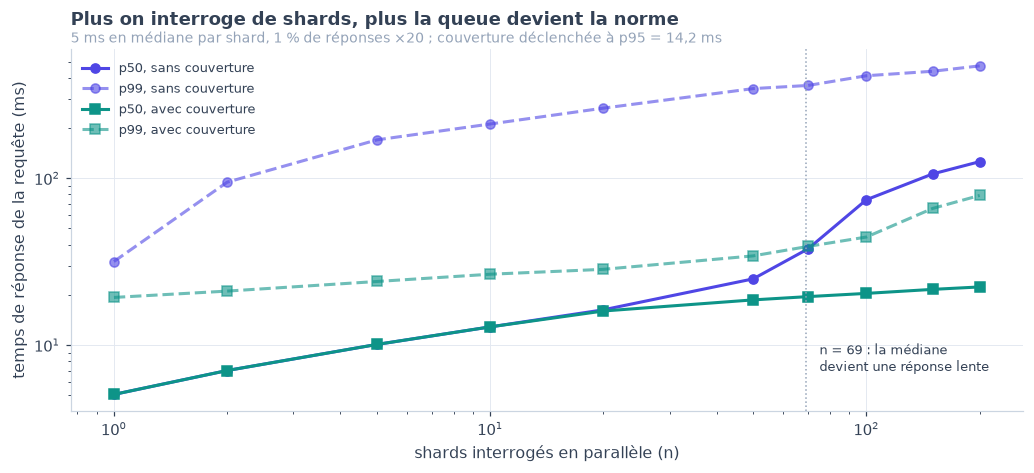

surcoût de la couverture : 5.0% de requêtes supplémentaires


,P(au moins une lente),p50 (ms),p99 (ms),p50 couvert,p99 couvert
n,,,,,
1,0.010,5.067,31.702,5.067,19.313
2,0.020,7.048,94.743,7.048,21.078
5,0.049,10.100,169.797,10.100,24.067
10,0.096,12.866,211.358,12.866,26.605
20,0.182,16.283,263.087,16.017,28.466
50,0.395,24.950,344.482,18.670,34.265
70,0.505,37.790,359.787,19.535,39.054
100,0.634,74.357,411.342,20.422,44.447
150,0.779,106.155,437.532,21.586,65.955


In [5]:
lent = P.lognormal_sampler(median=5.0, sigma=0.6, slow_p=0.01, slow_factor=20.0)
seul = lent(np.random.default_rng(1), 200_000)
d95 = np.percentile(seul, 95)

def couvert(r, size):
    t1, t2 = lent(r, size), lent(r, size)
    return np.where(t1 > d95, np.minimum(t1, d95 + t2), t1)

ns = [1, 2, 5, 10, 20, 50, 70, 100, 150, 200]
rows = []
for n in ns:
    a = P.scatter_gather_latency(n, 20_000, lent, seed=2)
    b = P.scatter_gather_latency(n, 20_000, couvert, seed=2)
    rows.append({"n": n, "P(au moins une lente)": 1 - 0.99 ** n,
                 "p50 (ms)": np.median(a), "p99 (ms)": np.percentile(a, 99),
                 "p50 couvert": np.median(b), "p99 couvert": np.percentile(b, 99)})
tab = pd.DataFrame(rows).set_index("n")

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(ns, tab["p50 (ms)"], "o-", color=INDIGO, label="p50, sans couverture")
ax.plot(ns, tab["p99 (ms)"], "o--", color=INDIGO, alpha=0.6, label="p99, sans couverture")
ax.plot(ns, tab["p50 couvert"], "s-", color=TEAL, label="p50, avec couverture")
ax.plot(ns, tab["p99 couvert"], "s--", color=TEAL, alpha=0.6, label="p99, avec couverture")
ax.axvline(69, color=GRAY, ls=":", lw=1)
ax.text(75, 7, "n = 69 : la médiane\ndevient une réponse lente", fontsize=8.5, color=SLATE)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("shards interrogés en parallèle (n)")
ax.set_ylabel("temps de réponse de la requête (ms)")
ax.set_title("Plus on interroge de shards, plus la queue devient la norme")
subtitle(ax, f"5 ms en médiane par shard, 1 % de réponses ×20 ; couverture déclenchée à p95 = {d95:.1f} ms".replace(".", ","))
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()
print(f"surcoût de la couverture : {np.mean(seul > d95):.1%} de requêtes supplémentaires")
tab.round(3)

La simulation confirme le calcul : le p99 dépasse 200 ms dès 10 shards, et la
médiane bondit entre 50 et 100 shards (de 25 ms à plus de 70 ms) quand la moitié des
requêtes rencontrent au moins une réponse lente. Avec la couverture, la médiane reste
autour de 20 ms et le p99 sous 80 ms jusqu'à 200 shards, pour 5 % de requêtes en plus.
La médiane couverte croît encore doucement avec $n$ : on attend toujours le maximum de
$n$ temps, même tronqués.

> **À retenir.** Une requête qui interroge $n$ shards vit dans la queue de la
> distribution de chacun : $1 - (1-p)^n$ approche vite 1. Les requêtes de couverture
> coupent cette queue pour quelques pour cent de charge ; mieux encore, une clé de
> partitionnement ou un index global qui évite le scatter/gather.

## Exercice 7.9 : index local ou global ? Un modèle de coût

**Énoncé.** Un site d'annonces de voitures est réparti en $n = 16$ shards par
identifiant d'annonce, avec des index secondaires sur la couleur et la marque. On compte
le coût en **opérations de shard** (une lecture ou écriture traitée par
un shard).

1. Exprimer le coût d'une écriture et d'une requête « couleur = rouge » (IDs seulement)
   pour un index local et pour un index global. Dans le cas global, une écriture touche
   le shard de l'annonce et ceux des deux termes : combien en moyenne ?
2. Soit $f$ la fraction de requêtes dans le trafic. Pour quelle valeur de $f$ les deux
   approches coûtent-elles autant ?
3. Même question si la requête doit renvoyer les annonces complètes (et pas seulement
   leurs IDs), sachant qu'une couleur correspond à des centaines d'annonces.
4. Quels inconvénients le modèle ne capture-t-il pas ?

**Rappels.** Un index local (par document) ne touche qu'un shard en écriture mais
impose de les interroger tous en lecture ; un index global (par terme) lit une seule
shard d'index par terme, mais une écriture peut en toucher plusieurs (cours 4, sections
*Local Secondary Indexes* et
*Global Secondary Indexes*).

**Solution.**

*1.* Index local : écriture $c_w = 1$, requête $c_r = n = 16$. Index global : la requête
lit le shard d'index du terme, $c_r = 1$ ; l'écriture touche l'ensemble des
shards distincts parmi celui de l'annonce et ceux de ses deux termes, trois tirages
(presque) indépendants : $E = 16\,(1 - (15/16)^3) \approx 2{,}82$.

*2.* Coût moyen par opération : local $(1-f) + 16 f$, global $2{,}82\,(1-f) + f$.
Égalité pour $1{,}82\,(1-f) = 15 f$, soit $f^* = 1{,}82 / 16{,}82 \approx 0{,}108$. Dès que
plus de 11 % des opérations sont des requêtes sur l'index, l'index global coûte moins
d'opérations.

*3.* Pour renvoyer les annonces, il faut ensuite lire chaque annonce sur sa
shard : des centaines d'annonces réparties par hachage touchent presque sûrement les 16
shards. Coût global de la requête : $1 + 16 = 17 > 16$ : l'index global ne gagne
**jamais** dans ce modèle. Il ne vaut que pour des requêtes sélectives (peu de
résultats), ou si les IDs suffisent (pagination, comptage).

*4.* Le modèle ignore : la **cohérence** de l'index global (une écriture sur trois
shards exige une transaction distribuée, ou bien une mise à jour asynchrone et des
lectures parfois périmées) ; la **latence de queue** du scatter/gather (exercice 7.8),
qui pénalise le local même à coût égal ; les **conjonctions** (couleur ET marque), qui
sont locales pour l'index local mais demandent de transférer et d'intersecter deux
listes de postings pour l'index global ; et la **scalabilité** : avec l'index local,
chaque requête occupe tous les shards, ajouter des nœuds n'augmente pas le débit
de requêtes.

écriture : local 1.00, global 2.822 (théorie 2,82)
requête « rouge » : local 16, global 1 ; 1595 annonces sur 16 shards
conjonction rouge ET Renault (458 résultats) : IDs transférés local 458, global 3039


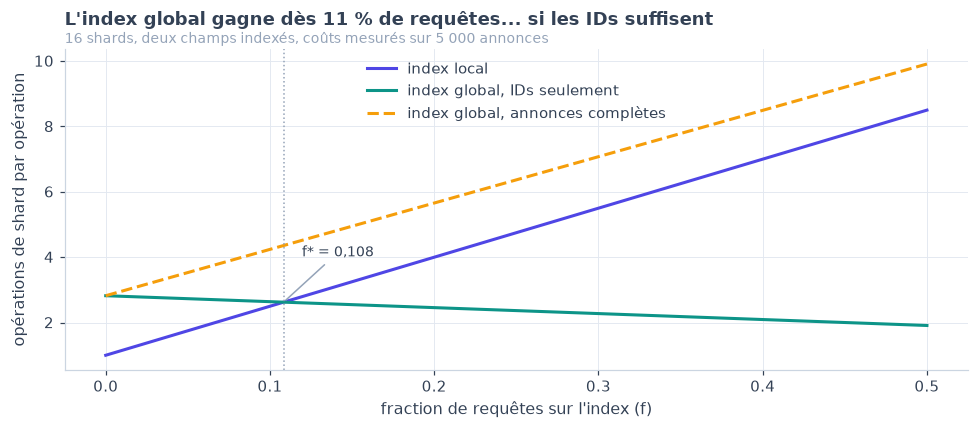

In [6]:
voitures = P.car_listings(5_000, seed=3)
loc, glo = P.LocalIndexDB(16), P.GlobalIndexDB(16)
cw_loc = np.mean([loc.put(v) for v in voitures])
cw_glo = np.mean([glo.put(v) for v in voitures])
ids, cr_glo = glo.query("color", "rouge")
_, cr_loc = loc.query("color", "rouge")
lues_docs = len({P.doc_shard(i, 16) for i in ids})
a, _, transf_loc = loc.query_and(("color", "rouge"), ("make", "Renault"))
_, _, transf_glo = glo.query_and(("color", "rouge"), ("make", "Renault"))
print(f"écriture : local {cw_loc:.2f}, global {cw_glo:.3f} (théorie 2,82)")
print(f"requête « rouge » : local {cr_loc}, global {cr_glo} ; {len(ids)} annonces sur {lues_docs} shards")
print(f"conjonction rouge ET Renault ({len(a)} résultats) : IDs transférés local {transf_loc}, global {transf_glo}")

f = np.linspace(0, 0.5, 200)
fstar = (cw_glo - 1) / (16 - 1 + cw_glo - 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(f, (1 - f) * cw_loc + f * cr_loc, color=INDIGO, label="index local")
ax.plot(f, (1 - f) * cw_glo + f * cr_glo, color=TEAL, label="index global, IDs seulement")
ax.plot(f, (1 - f) * cw_glo + f * (cr_glo + lues_docs), color=AMBER, ls="--", label="index global, annonces complètes")
ax.axvline(fstar, color=GRAY, ls=":", lw=1)
ax.annotate(f"f* = {fstar:.3f}".replace(".", ","), (fstar, (1 - fstar) * cw_glo + fstar), (12, 30),
            textcoords="offset points", fontsize=9, color=SLATE, arrowprops=dict(arrowstyle="-", color=GRAY))
ax.set_xlabel("fraction de requêtes sur l'index (f)")
ax.set_ylabel("opérations de shard par opération")
ax.set_title("L'index global gagne dès 11 % de requêtes... si les IDs suffisent")
subtitle(ax, "16 shards, deux champs indexés, coûts mesurés sur 5 000 annonces")
ax.legend()
plt.tight_layout(); plt.show()

Les mesures retrouvent les coûts théoriques : 2,8 shards touchés par écriture avec
l'index global, 16 lectures pour une requête avec l'index local, et des annonces rouges
réparties sur les 16 shards. La conjonction illustre le dernier point : l'index local
ne renvoie que les résultats déjà intersectés, l'index global doit rapatrier les deux
listes complètes.

> **À retenir.** L'index global échange des écritures plus chères (et plus difficiles à
> garder cohérentes) contre des lectures qui ne touchent qu'un shard. Il convient aux
> charges dominées par des lectures **sélectives** ; l'index local, plus simple, convient
> aux charges d'écriture et aux requêtes qui renvoient de toute façon beaucoup de
> résultats.

## Exercice 7.10 : rééquilibrage automatique, durée et cascade

**Énoncé.** Un cluster de 10 nœuds porte 4 To par nœud. Le réseau offre 10 Gbit/s par
nœud, mais le rééquilibrage est bridé à 25 % de cette bande passante pour ne pas gêner
le trafic.

1. On ajoute un 11e nœud. Quel volume doit-il recevoir, et en combien de temps (la
   réception par le nouveau nœud est le goulot) ?
2. Un nœud est déclaré mort par erreur : ses 4 To doivent être reconstruits sur les 9
   autres à partir des répliques, chacun recevant et envoyant en parallèle. Combien de
   temps dure cette charge supplémentaire ?
3. Avec le modèle `P.rebalancing_cascade`, déterminer pour quelles charges de base
   (utilisation moyenne des nœuds) et quels surcoûts de migration un pic temporaire sur
   un nœud dégénère en défaillance totale. Quel est l'effet de la patience du détecteur
   (nombre de minutes de lenteur avant d'exclure un nœud) ?

**Rappels.** Le rééquilibrage déplace de gros volumes et charge le réseau et les nœuds ;
combiné à une détection automatique des pannes, il peut transformer un nœud lent en
défaillance en cascade, d'où l'intérêt d'un humain dans la boucle (cours 2, section
*Operations: Automatic Versus Manual Rebalancing*).

**Solution.**

*1.* Le nouveau nœud doit recevoir sa part : $40/11 \approx 3{,}64$ To. Bande passante
bridée : 2,5 Gbit/s = 312,5 Mo/s. Durée : $3{,}64 \cdot 10^{12} / 3{,}125 \cdot 10^8
\approx 11\,600$ s, soit **3 h 15**. Sans bridage, 48 minutes, mais au prix du trafic
normal du nœud.

*2.* Chaque survivant reçoit $4/9 \approx 0{,}44$ To à 312,5 Mo/s : $\approx 1\,420$ s,
soit **24 minutes** pendant lesquelles chaque nœud consacre un quart de son réseau (et
des entrées-sorties disque) à la reconstruction, sur un cluster qui a déjà perdu 10 % de
sa capacité.

*3.* Voir les simulations ci-dessous. Retenons le mécanisme : exclure un nœud répartit sa
charge sur les autres (+11 % chacun avec 10 nœuds) et y ajoute le coût des transferts ;
si les survivants étaient déjà proches de la saturation, leur temps de réponse explose
à leur tour, le détecteur les exclut, et ainsi de suite.

nouveau nœud : 3.64 To en 3.23 h (sans bridage : 48 min)
reconstruction après exclusion : 24 min


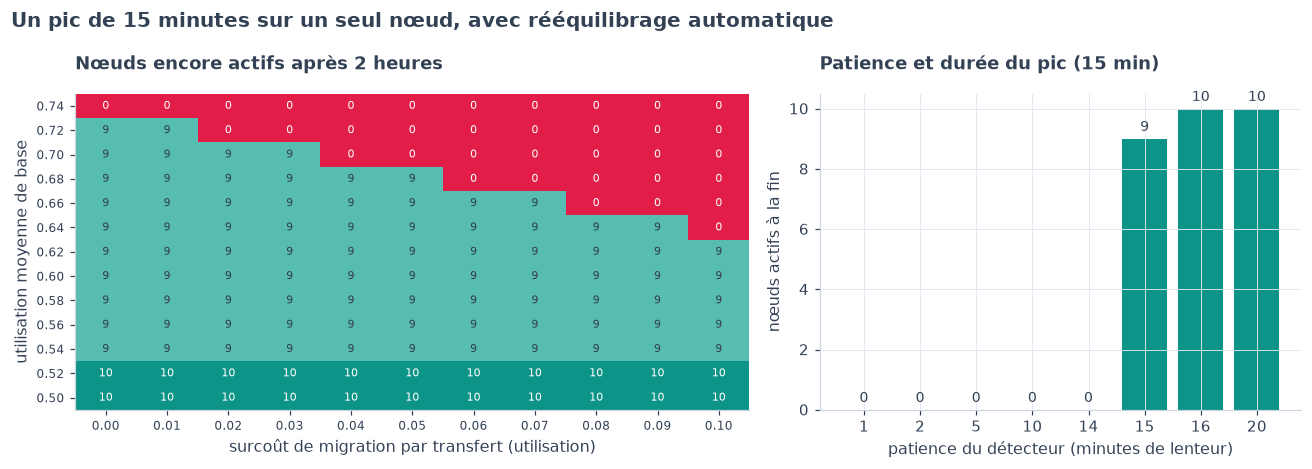

In [7]:
vol_nouveau = 40 / 11
debit = 10e9 / 8 * 0.25
print(f"nouveau nœud : {vol_nouveau:.2f} To en {vol_nouveau * 1e12 / debit / 3600:.2f} h "
      f"(sans bridage : {vol_nouveau * 1e12 / (debit * 4) / 60:.0f} min)")
print(f"reconstruction après exclusion : {4 / 9 * 1e12 / debit / 60:.0f} min")

bases = np.round(np.arange(0.50, 0.76, 0.02), 2)
couts = np.round(np.arange(0.0, 0.11, 0.01), 2)
grille = np.array([[P.rebalancing_cascade(base_util=b, migration_cost=c)["actifs"][-1] for c in couts] for b in bases])
patiences = [1, 2, 5, 10, 14, 15, 16, 20]
surv_pat = [P.rebalancing_cascade(patience=p)["actifs"][-1] for p in patiences]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.4, 1]})
im = axes[0].imshow(grille, origin="lower", cmap="ddia_div", vmin=0, vmax=10, aspect="auto")
axes[0].set_xticks(range(len(couts))); axes[0].set_xticklabels([f"{c:.2f}" for c in couts], fontsize=8)
axes[0].set_yticks(range(len(bases))); axes[0].set_yticklabels([f"{b:.2f}" for b in bases], fontsize=8)
for i in range(len(bases)):
    for j in range(len(couts)):
        axes[0].text(j, i, grille[i, j], ha="center", va="center", fontsize=7.5,
                     color="white" if grille[i, j] in (0, 10) else SLATE)
axes[0].set_xlabel("surcoût de migration par transfert (utilisation)")
axes[0].set_ylabel("utilisation moyenne de base")
axes[0].set_title("Nœuds encore actifs après 2 heures")
axes[0].grid(False)
axes[1].bar([str(p) for p in patiences], surv_pat, color=[ROSE if s < 5 else TEAL for s in surv_pat])
axes[1].set_xlabel("patience du détecteur (minutes de lenteur)")
axes[1].set_ylabel("nœuds actifs à la fin")
axes[1].set_title("Patience et durée du pic (15 min)")
annotate_bars(axes[1], "{:.0f}")
finish(fig, "Un pic de 15 minutes sur un seul nœud, avec rééquilibrage automatique")
plt.show()

La carte montre trois régimes. Sous 54 % d'utilisation de base, le pic ne suffit pas à
faire dépasser le seuil de détection : rien ne se passe (10 nœuds). Entre 54 et 62 %,
le nœud en pic est exclu à tort, mais les survivants absorbent sa charge : on perd un
nœud (9). Au-delà, l'exclusion déclenche la cascade et le cluster entier finit exclu
(0), d'autant plus tôt que les transferts sont coûteux : dès 64 % avec un surcoût de
0,10, à 74 % même sans surcoût. Il n'y a pas d'état intermédiaire entre 9 et 0 : c'est
la signature d'une défaillance en cascade. La patience du détecteur n'aide que si elle
atteint la durée du pic : à 15 minutes, le nœud est exclu à la toute fin du pic, quand
la charge retombe, sans cascade ; à 16 minutes et plus, il n'est jamais exclu et le pic
passe sans dommage. Un détecteur patient, ou un humain qui valide le rééquilibrage,
est une protection ; un détecteur nerveux est un amplificateur.

> **À retenir.** Déplacer des téraoctets prend des heures et charge tout le cluster.
> Automatiser à la fois la détection de panne et le rééquilibrage revient à répondre à
> la surcharge par davantage de charge : au-delà d'un seuil d'utilisation, un simple pic
> devient une panne totale. On garde de la marge, on borne le débit des transferts, et
> on laisse souvent un humain décider.

## Exercice 7.11 : ranger des locataires dans des shards

**Énoncé.** Un service SaaS compte 2 000 locataires (tenants) dont la taille suit une loi
log-normale (médiane 2 Go, quelques géants), générée par
`T.tenant_sizes(2000, seed=4)`. Un shard peut contenir 250 Go.

1. Combien de shards faut-il si l'on donne un shard par locataire ? Si l'on regroupe
   les locataires (first-fit decreasing, `T.pack_tenants`) ? Combien de locataires sont
   trop gros pour un seul shard ?
2. Un locataire lance un traitement lourd (+0,3 d'utilisation) sur un shard utilisé à
   60 %. Combien de locataires subissent un ralentissement, et de quel facteur, selon le
   nombre de locataires par shard ?
3. Les locataires grossissent (0 à 12 % par trimestre). Comparer, sur trois ans, deux
   politiques de déplacement quand un shard déborde : déplacer les plus petits ou les
   plus gros locataires.

**Rappels.** Le sharding par locataire isole les ressources, les permissions et les
pannes, et facilite sauvegarde, restauration et conformité ; mais il suppose qu'un
locataire tienne sur un nœud, et regrouper de petits locataires pose la question de leur
déplacement quand ils grossissent (cours 5, section *Sharding for Multitenancy*).

**Solution.**

*1.* Un shard par locataire : 2 000 shards, la plupart presque vides (la médiane est à
2 Go pour 250 Go de capacité), donc 2 000 fois le surcoût fixe d'un shard. Le
regroupement remplit les shards presque à ras bord : le nombre de shards approche le
minimum théorique, volume total / capacité. Les locataires de plus de 250 Go sont
ceux qu'il faudra sharder eux-mêmes (calcul ci-dessous).

*2.* Sur un shard à 60 %, le temps de réponse relatif vaut $1/(1-0{,}6) = 2{,}5$ ; avec
le traitement lourd, $1/(1-0{,}9) = 10$ : **4 fois plus lent** pour tous les autres
locataires du shard. Avec $g$ locataires par shard, $g - 1$ voisins en souffrent : la
fraction touchée est $(g-1)/(N-1)$, soit 0 avec un shard par locataire, et 100 % dans une
base unique.

*3.* Déplacer les plus petits locataires minimise le **volume** transféré (on déplace
peu de données à chaque fois), mais multiplie le **nombre** de déplacements ; déplacer
les plus gros fait l'inverse. Le choix dépend de ce qui coûte : la bande passante (petits)
ou les opérations délicates de bascule d'un client (gros).

In [8]:
from ddia import partitioning_tenants as T

tailles = T.tenant_sizes(2000, seed=4)
CAP = 250.0
shards, geants = T.pack_tenants(tailles, CAP)
remplissage = np.array([tailles[s].sum() / CAP for s in shards])
print(f"volume total : {tailles.sum() / 1000:.1f} To ; médiane {np.median(tailles):.1f} Go ; "
      f"plus gros : {tailles.max():.0f} Go")
print(f"un shard par locataire : 2000 shards, remplissage moyen {tailles[tailles <= CAP].mean() / CAP:.1%}")
print(f"regroupés : {len(shards)} shards (minimum théorique {math.ceil(tailles[tailles <= CAP].sum() / CAP)}), "
      f"remplissage moyen {remplissage.mean():.1%}")
print(f"locataires trop gros pour un shard : {len(geants)} ({', '.join(f'{tailles[g]:.0f} Go' for g in geants)})")

volume total : 13.4 To ; médiane 2.0 Go ; plus gros : 415 Go
un shard par locataire : 2000 shards, remplissage moyen 2.6%
regroupés : 52 shards (minimum théorique 52), remplissage moyen 99.7%
locataires trop gros pour un shard : 1 (415 Go)


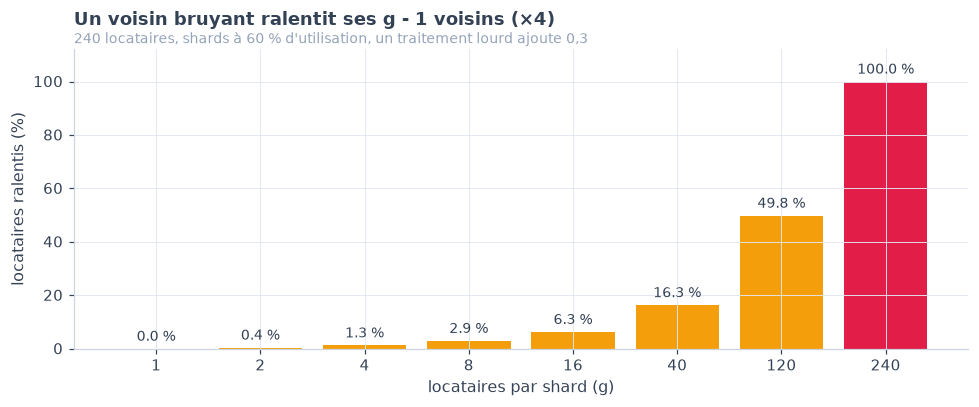

In [9]:
N_LOC = 240
gs = [1, 2, 4, 8, 16, 40, 120, 240]
touches, facteurs = [], []
for g in gs:
    shard_of = np.repeat(np.arange(N_LOC // g), g)
    charges = np.full(N_LOC, 0.6 / g)
    ralent = T.noisy_neighbor_slowdown(charges, shard_of, heavy=0, extra=0.3)
    autres = np.delete(ralent, 0)
    touches.append(np.mean(autres > 1.01))
    facteurs.append(autres.max())

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar([str(g) for g in gs], np.array(touches) * 100, color=[TEAL if g == 1 else (ROSE if g == N_LOC else AMBER) for g in gs])
annotate_bars(ax, "{:.1f} %")
ax.set_xlabel("locataires par shard (g)")
ax.set_ylabel("locataires ralentis (%)")
ax.set_ylim(0, 112)
ax.set_title(f"Un voisin bruyant ralentit ses g - 1 voisins (×{max(facteurs):.0f})".replace(".", ","))
subtitle(ax, f"{N_LOC} locataires, shards à 60 % d'utilisation, un traitement lourd ajoute 0,3")
plt.tight_layout(); plt.show()

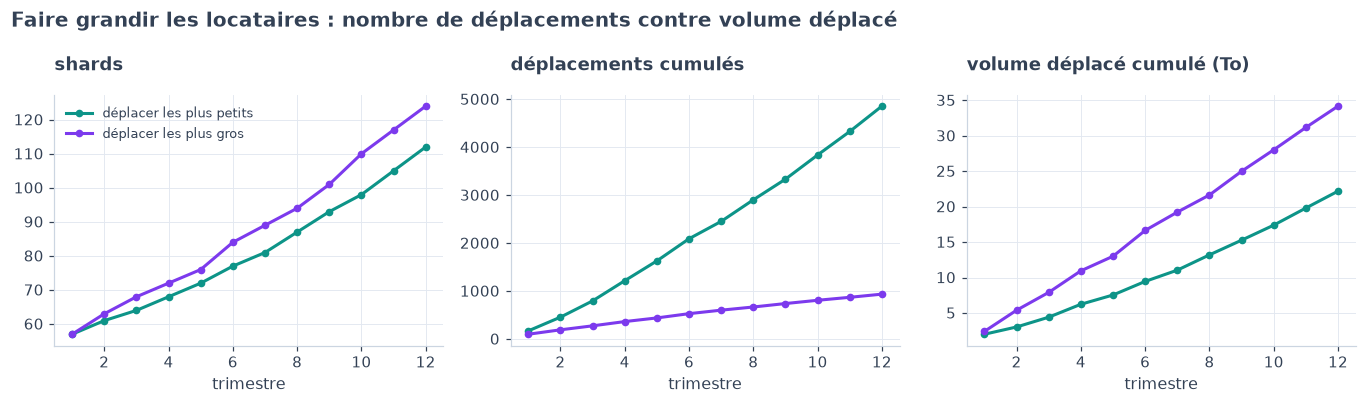

,shards à la fin,déplacements,volume déplacé (To),locataires trop gros à la fin
smallest,112.0,4857.0,22.191,9.0
largest,124.0,936.0,34.183,9.0


In [10]:
croissance = np.random.default_rng(5).uniform(0, 0.12, tailles.size)
res = {pol: T.simulate_tenant_growth(tailles, croissance, CAP, 12, policy=pol) for pol in ["smallest", "largest"]}
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.7))
trim = np.arange(1, 13)
for pol, c, nom in [("smallest", TEAL, "déplacer les plus petits"), ("largest", VIOLET, "déplacer les plus gros")]:
    axes[0].plot(trim, res[pol]["shards"], "o-", color=c, ms=4, label=nom)
    axes[1].plot(trim, np.cumsum(res[pol]["deplaces"]), "o-", color=c, ms=4)
    axes[2].plot(trim, np.cumsum(res[pol]["volume"]) / 1000, "o-", color=c, ms=4)
axes[0].set_title("shards"); axes[1].set_title("déplacements cumulés"); axes[2].set_title("volume déplacé cumulé (To)")
for ax in axes:
    ax.set_xlabel("trimestre")
axes[0].legend(fontsize=8.5)
finish(fig, "Faire grandir les locataires : nombre de déplacements contre volume déplacé")
plt.show()
pd.DataFrame({pol: {"shards à la fin": r["shards"][-1], "déplacements": r["deplaces"].sum(),
                    "volume déplacé (To)": r["volume"].sum() / 1000, "locataires trop gros à la fin": r["trop_gros"][-1]}
              for pol, r in res.items()}).T

Le regroupement divise le nombre de shards par près de quarante par rapport à un shard par
locataire. Les quelques géants (le tableau en donne la liste) sortent du cadre : il faut
les sharder par une autre clé, comme une base sans multi-location. Le voisin bruyant
ralentit d'un facteur 4 tous ses voisins de shard : la fraction touchée passe de 0 (un
shard par locataire) à 100 % (base unique), ce qui chiffre l'arbitrage entre isolation et
surcoût. Enfin, la croissance impose des déplacements continus : la politique « plus
petits d'abord » déplace beaucoup plus de locataires, mais moins de données que la
politique « plus gros d'abord », et finit avec moins de shards. Au bout de trois ans, neuf
locataires ont dépassé la capacité d'un shard : la question des géants revient sans cesse.

> **À retenir.** Le sharding par locataire est un arbitrage : un shard par locataire
> isole parfaitement mais coûte cher en surcoût fixe, des shards partagés sont économes
> mais exposent aux voisins bruyants et imposent de déplacer les locataires qui
> grandissent. Les géants, eux, ramènent au sharding classique.

## Exercice 7.12 : faut-il sharder ?

**Énoncé.** Une application gère aujourd'hui 2 To de données et 5 000 écritures/s, avec
une croissance de 40 % par an. Une machine récente peut stocker confortablement 30 To
sur SSD NVMe et soutenir 50 000 écritures/s pour cette charge.

1. Dans combien d'années une seule machine ne suffira-t-elle plus ?
2. Une transaction typique touche $k$ enregistrements. Si les enregistrements sont
   répartis au hasard sur $n$ shards, quelle est la probabilité qu'elle reste sur un seul
   shard ? Application à $k = 3$, $n = 8$.
3. Une transaction locale prend 2 ms, une transaction distribuée 10 ms (validation en
   deux phases). Quel est le temps moyen pour $n = 8$ et $k = 3$ ? Que change une clé de
   partitionnement qui regroupe les enregistrements d'un même client, si une transaction
   touche deux enregistrements du client et un enregistrement de stock ?

**Rappels.** Le sharding sert la scalabilité quand les données ou le débit d'écriture
dépassent une machine ; il complique les requêtes et impose des transactions
distribuées entre shards, bien plus lentes (cours 5, section *Pros and Cons of
Sharding* ; chapitre 8).

**Solution.**

*1.* Stockage : $2 \times 1{,}4^t = 30 \Rightarrow t = \ln 15 / \ln 1{,}4 \approx 8$ ans.
Écritures : $\ln 10 / \ln 1{,}4 \approx 6{,}8$ ans. Le débit d'écriture est la limite, à
près de **sept ans** : il est raisonnable de ne pas sharder aujourd'hui (la réplication
suffit pour la tolérance aux pannes et les lectures), en gardant une clé de
partitionnement naturelle en tête pour plus tard.

*2.* Le premier enregistrement fixe le shard, chacun des $k - 1$ autres doit tomber sur
le même : $(1/n)^{k-1}$. Pour $k = 3$, $n = 8$ : $1/64 \approx 1{,}6$ %. Presque toutes
les transactions deviennent distribuées.

*3.* $0{,}016 \times 2 + 0{,}984 \times 10 \approx 9{,}9$ ms, cinq fois plus que sans
sharding. Avec la clé « client », les deux enregistrements du client sont ensemble ; seul
le stock est ailleurs, sur le même shard avec probabilité $1/8$ : temps moyen
$0{,}125 \times 2 + 0{,}875 \times 10 = 9$ ms. Mieux, mais insuffisant : il faut aussi
revoir le modèle (réserver le stock de façon asynchrone, ou partitionner le stock par
entrepôt et router les commandes vers l'entrepôt), sans quoi le sharding coûte plus qu'il
ne rapporte.

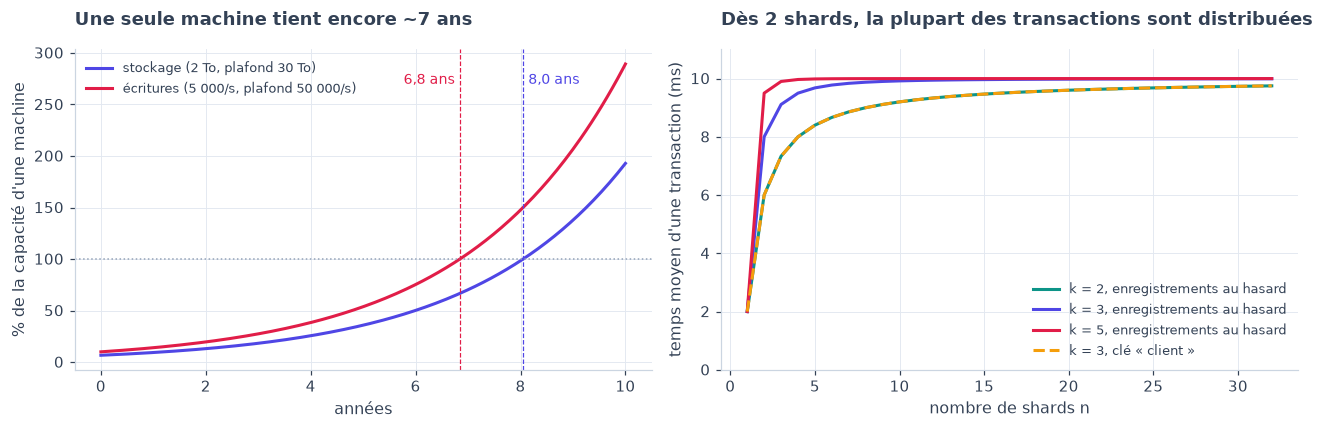

P(un seul shard), k = 3, n = 8 : 0.0156


In [11]:
annees = np.linspace(0, 10, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot(annees, 2 * 1.4 ** annees / 30 * 100, color=INDIGO, label="stockage (2 To, plafond 30 To)")
ax.plot(annees, 5_000 * 1.4 ** annees / 50_000 * 100, color=ROSE, label="écritures (5 000/s, plafond 50 000/s)")
ax.axhline(100, color=GRAY, ls=":", lw=1)
for val, c, ha in [(math.log(15) / math.log(1.4), INDIGO, "left"), (math.log(10) / math.log(1.4), ROSE, "right")]:
    ax.axvline(val, color=c, ls="--", lw=0.8)
    ax.text(val + (0.1 if ha == "left" else -0.1), 270, f"{val:.1f} ans".replace(".", ","), color=c, fontsize=9, ha=ha)
ax.set_xlabel("années"); ax.set_ylabel("% de la capacité d'une machine")
ax.set_title("Une seule machine tient encore ~7 ans")
ax.legend(fontsize=8.5, loc="upper left")
ax = axes[1]
ns = np.arange(1, 33)
for k, c in [(2, TEAL), (3, INDIGO), (5, ROSE)]:
    p = np.array([T.single_shard_probability(n, k) for n in ns])
    ax.plot(ns, 2 * p + 10 * (1 - p), color=c, label=f"k = {k}, enregistrements au hasard")
p_cli = 1 / ns
ax.plot(ns, 2 * p_cli + 10 * (1 - p_cli), color=AMBER, ls="--", label="k = 3, clé « client »")
ax.set_xlabel("nombre de shards n"); ax.set_ylabel("temps moyen d'une transaction (ms)")
ax.set_title("Dès 2 shards, la plupart des transactions sont distribuées")
ax.legend(fontsize=8.5, loc="lower right")
ax.set_ylim(0, 11)
finish(fig)
plt.show()
print(f"P(un seul shard), k = 3, n = 8 : {T.single_shard_probability(8, 3):.4f}")

Les deux courbes de gauche croisent la capacité d'une machine vers 6,8 et 8 ans. À
droite, le temps moyen d'une transaction rejoint presque aussitôt celui d'une transaction
distribuée dès que les enregistrements sont dispersés ; la clé « client » ramène le cas
$k = 3$ à celui de $k = 2$ (les deux courbes se confondent), sans plus : le gain de capacité du sharding
se paie en latence et en complexité, sauf si le modèle de données permet de garder les
transactions sur un seul shard.

> **À retenir.** Une machine moderne va loin : on ne sharde que lorsque le volume ou le
> débit d'**écriture** l'exige (la réplication suffit pour les lectures). Le jour venu,
> tout se joue sur la clé de partitionnement : si les transactions courantes ne tiennent
> pas dans un seul shard, le sharding les rend toutes distribuées.